# RQ3 - Do translators leave a fingerprint? Identifying the translation model from the text

**Question.** Given an English text produced by a round trip (T1, T2 or T3), can a classifier tell which translator
produced it?

**Protocol.**
- **Classes:** the translators discovered from the finalized datasets (currently MADLAD-400-3B, NLLB-200-1.3B and
  Qwen3-4B). Chance is computed as 1/K at run time, and a new translator (e.g. Phi-4-mini) is added automatically.
- **Inputs:** only the **English translated text**. Model names, metadata and source labels are never features.
- **Balance:** the matched cohort, i.e. documents complete for every translator, so each translator contributes the
  *same* documents at every round and classes are exactly balanced.
- **Splitting:** grouped folds over **original article IDs** (5 folds × 5 shufflings). One article's texts (every
  source, translator and round) are always on the same side, so the classifier can never match a test text to a
  training text of the same content.
- **Primary experiment:** train on the pooled T1-T3 texts of the training articles, then evaluate each round
  separately. Further experiments train per round and cross-round.
- **Uncertainty:** the 31 articles, not individual texts, are the resampling unit in the bootstrap CIs.

> **Public copy** by Samer Ahmed. This notebook was executed end to end from a clean kernel on 2026-11-01, and its saved outputs (tables, figures, interpretation) are shown as they were produced. The code cells call a shared research package and local, unpublished text tables (XSum texts and their translations) that are not part of this folder. They live in the development workspace (`Sam/` on branch `feature/sam-experiments`), so re-running needs that workspace. The aggregate result tables are in [`../results/`](../results/) and the figures in [`../figures/`](../figures/).

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "src" / "sot_research").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sot_research import analysis, classify, corpus, features, paths, plots

%matplotlib inline
plots.setup()
pd.set_option("display.width", 200, "display.max_columns", 40, "display.precision", 3)
CFG = corpus.research_config()
SEED, NB, NR = CFG["seed"], CFG["bootstrap_samples"], CFG["cv_repeats"]
print("python", sys.version.split()[0], "|", Path(sys.executable).parent.parent.name, "| pandas", pd.__version__)

D = analysis.load(require_text=True, pairs=False)
TR, NAMES, COL = D["translators"], D["names"], D["colors"]
OUT = paths.results("rq3")
F = D["features"]
STYLE = features.style_columns(F)
en = corpus.english(D["texts"]).merge(F[["text_id", "n_words", "n_sentences"] + STYLE], on="text_id", how="left")
en = classify.add_length_cols(en)
pool = en[en.translator.isin(TR) & en.stage.isin(["T1", "T2", "T3"]) & en.item_id.isin(D["matched_items"])].copy()
K = len(TR)
CHANCE = 1 / K
print(f"K = {K} translators -> chance = {CHANCE:.3f}")
bal = pool.groupby(["stage", "translator"]).size().unstack().rename(columns=NAMES)
display(bal.rename_axis(index="texts per stage"))
assert bal.nunique(axis=1).eq(1).all(), "classes must be balanced (same documents per translator)"
print("articles:", pool.article_id.nunique(), "| documents:", pool.item_id.nunique(), "| texts:", len(pool))

python 3.12.15 | .venv-research | pandas 2.2.3


K = 3 translators -> chance = 0.333


translator,MADLAD-400-3B,NLLB-200-1.3B,Qwen3-4B
texts per stage,,,
T1,193,193,193
T2,193,193,193
T3,193,193,193


articles: 31 | documents: 193 | texts: 1737


## 1. Descriptive confound check: length and segmentation

In [2]:
t0w = en[en.stage == "T0"].set_index("item_id")[["n_words", "n_sentences"]]
d = pool.join(t0w, on="item_id", rsuffix="_t0")
d["word_ratio"] = d.n_words / d.n_words_t0
d["sentence_ratio"] = d.n_sentences / d.n_sentences_t0
desc = d.groupby(["translator", "stage"])[["n_words", "word_ratio", "sentence_ratio", "sent_len_mean",
                                          "punct_01", "mattr"]].mean()
desc.index = [(NAMES[a], b) for a, b in desc.index]
display(desc.rename(columns={"punct_01": "comma rate"}).round(3))
desc.to_csv(OUT / "length_segmentation_descriptives.csv")
print("Sources are balanced by construction (same documents per translator):")
display(pool.groupby(["source_label", "translator"]).size().unstack().rename(columns=NAMES).head(8))

,n_words,word_ratio,sentence_ratio,sent_len_mean,comma rate,mattr
"(MADLAD-400-3B, T1)",228.813,0.947,0.914,23.346,0.039,0.821
"(MADLAD-400-3B, T2)",222.161,0.923,0.867,24.523,0.040,0.820
"(MADLAD-400-3B, T3)",220.114,0.916,0.852,24.995,0.041,0.820
"(NLLB-200-1.3B, T1)",236.570,0.977,1.011,21.144,0.036,0.827
"(NLLB-200-1.3B, T2)",237.016,0.978,1.051,20.492,0.036,0.826
"(NLLB-200-1.3B, T3)",241.171,0.989,1.138,19.939,0.036,0.820
"(Qwen3-4B, T1)",233.554,0.983,1.007,21.234,0.046,0.831
"(Qwen3-4B, T2)",232.378,0.980,1.007,21.177,0.047,0.831
"(Qwen3-4B, T3)",232.093,0.978,1.007,21.127,0.046,0.832


Sources are balanced by construction (same documents per translator):


translator,MADLAD-400-3B,NLLB-200-1.3B,Qwen3-4B
source_label,,,
BigScience,84,84,84
Eleuther-AI,78,78,78
Human,87,87,87
LLAMA,81,81,81
OpenAI,84,84,84
PaLM,84,84,84
Tsinghua,81,81,81


## 2. Main experiment: train on pooled T1-T3, evaluate per round

In [3]:
SENT = ["sent_len_mean", "sent_len_sd", "punct_00", "dep_ROOT", "cap_rate"]
STYLE_NOSENT = [c for c in STYLE if c not in SENT]
MODELS = {"tfidf_word": None, "tfidf_char": None, "stylometric": STYLE, "stylometric_no_sentence": STYLE_NOSENT,
          "length_only": classify.LENGTH_COLS}
def model_kind(m):
    return "stylometric" if m.startswith("stylometric") else m
EVALS = {s: pool[pool.stage == s] for s in ["T1", "T2", "T3"]}
runs = []
for mname, cols in MODELS.items():
    p = classify.grouped_cv(pool, EVALS, "translator", model_kind(mname), cols=cols, n_splits=CFG["cv_folds"],
                            repeats=NR, seed=SEED)
    runs.append(p.assign(model=mname))
preds = pd.concat(runs, ignore_index=True)
preds["stage"] = preds.eval_set
LAB = TR
sc = classify.scores(preds, ["model", "stage"], LAB, n_boot=1000, seed=SEED)
sc_all = classify.scores(preds, ["model"], LAB, n_boot=1000, seed=SEED).assign(stage="T1-T3")
scores = pd.concat([sc, sc_all], ignore_index=True)
scores.to_csv(OUT / "scores_main.csv", index=False)
t = scores.copy()
t["macro-F1 [95% CI]"] = t.apply(lambda r: f"{r.macro_f1:.3f} [{r.macro_f1_ci_low:.3f}, {r.macro_f1_ci_high:.3f}]", axis=1)
t["accuracy (±SD)"] = t.apply(lambda r: f"{r.accuracy:.3f} ± {r.accuracy_sd:.3f}", axis=1)
display(t.pivot_table(index="model", columns="stage", values="macro-F1 [95% CI]", aggfunc="first").reindex(list(MODELS)))
display(t.pivot_table(index="model", columns="stage", values="accuracy (±SD)", aggfunc="first").reindex(list(MODELS)))
print("texts per round:", sorted(sc.n_texts.unique()), "| articles:", sorted(sc.n_articles.unique()), "| chance:", round(CHANCE, 3))
splits = pd.DataFrame([{"repeat": r, "seed": SEED + r, "article_id": a, "fold": f}
                       for r in range(NR) for a, f in classify.article_folds(pool.article_id, CFG["cv_folds"], SEED + r).items()])
splits.to_csv(OUT / "splits.csv", index=False)

stage,T1,T1-T3,T2,T3
model,,,,
tfidf_word,"0.549 [0.506, 0.590]","0.569 [0.524, 0.616]","0.575 [0.526, 0.621]","0.583 [0.535, 0.631]"
tfidf_char,"0.723 [0.676, 0.766]","0.730 [0.689, 0.772]","0.732 [0.689, 0.771]","0.736 [0.693, 0.782]"
stylometric,"0.588 [0.548, 0.626]","0.603 [0.565, 0.642]","0.610 [0.569, 0.646]","0.611 [0.567, 0.656]"
stylometric_no_sentence,"0.597 [0.558, 0.637]","0.611 [0.570, 0.651]","0.618 [0.579, 0.659]","0.618 [0.574, 0.658]"
length_only,"0.449 [0.417, 0.477]","0.476 [0.445, 0.504]","0.478 [0.450, 0.507]","0.501 [0.466, 0.533]"


stage,T1,T1-T3,T2,T3
model,,,,
tfidf_word,0.578 ± 0.010,0.597 ± 0.008,0.603 ± 0.011,0.609 ± 0.008
tfidf_char,0.726 ± 0.010,0.733 ± 0.008,0.734 ± 0.010,0.739 ± 0.012
stylometric,0.588 ± 0.010,0.604 ± 0.009,0.611 ± 0.006,0.612 ± 0.012
stylometric_no_sentence,0.597 ± 0.013,0.612 ± 0.013,0.619 ± 0.013,0.619 ± 0.015
length_only,0.450 ± 0.005,0.477 ± 0.004,0.478 ± 0.006,0.501 ± 0.007


texts per round: [579] | articles: [31] | chance: 0.333


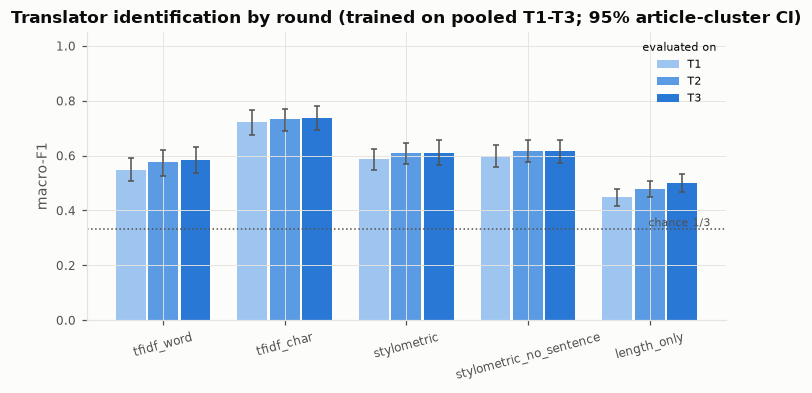

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
names = list(MODELS)
w = 0.8 / 3
for i, s in enumerate(["T1", "T2", "T3"]):
    g = sc[sc.stage == s].set_index("model").reindex(names)
    x = np.arange(len(names)) + (i - 1) * w
    ax.bar(x, g.macro_f1, width=w * 0.92, color=["#9ec5f0", "#5a9be4", "#2a78d6"][i], label=s)
    ax.errorbar(x, g.macro_f1, yerr=[g.macro_f1 - g.macro_f1_ci_low, g.macro_f1_ci_high - g.macro_f1], fmt="none",
                ecolor=plots.INK2, capsize=2, lw=1)
ax.axhline(CHANCE, color=plots.INK2, ls=":", lw=1)
ax.text(len(names) - 0.5, CHANCE, f"chance 1/{K}", va="bottom", ha="right", fontsize=7, color=plots.INK2)
ax.set_xticks(range(len(names)), names, rotation=15)
ax.set_ylim(0, 1.05)
ax.set_ylabel("macro-F1")
ax.legend(title="evaluated on", fontsize=7, title_fontsize=7)
ax.set_title("Translator identification by round (trained on pooled T1-T3; 95% article-cluster CI)")
plots.save(fig, "rq3_macro_f1_by_model_round")
plt.show()

## 3. Confusion matrices and per-class results

best model (pooled): tfidf_char


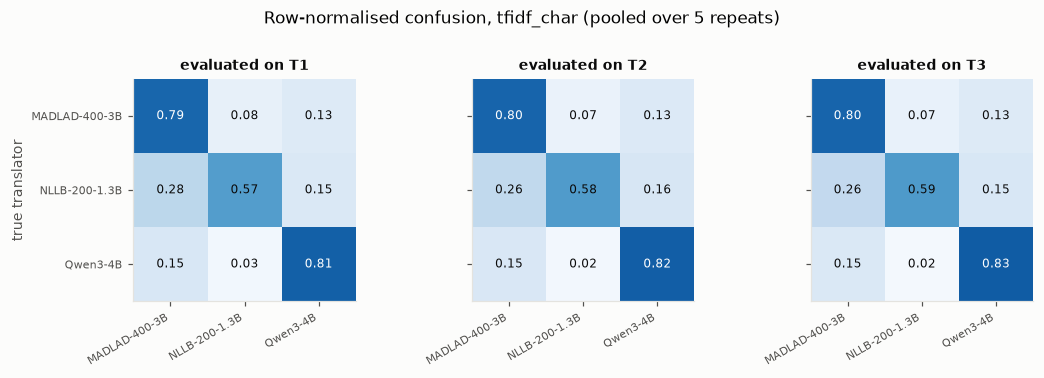

f1               precision               recall              
stage             T1     T2     T3        T1     T2     T3     T1     T2     T3
class                                                                          
MADLAD-400-3B  0.710  0.722  0.724     0.645  0.658  0.662  0.790  0.799  0.799
NLLB-200-1.3B  0.681  0.694  0.698     0.837  0.864  0.859  0.574  0.580  0.588
Qwen3-4B       0.779  0.779  0.786     0.747  0.739  0.747  0.815  0.824  0.829

In [5]:
best = sc_all.sort_values("macro_f1", ascending=False).model.iloc[0]
print("best model (pooled):", best)
pc = classify.per_class(preds, ["model", "stage"], LAB)
pc.to_csv(OUT / "per_class.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(3.2 * 3 + 0.5, 3.2))
conf = []
for ax, s in zip(axes, ["T1", "T2", "T3"]):
    part = preds[(preds.model == best) & (preds.stage == s)]
    cm = classify.confusion(part, LAB)
    conf.append(classify.confusion(part, LAB, normalize=False).stack().rename("count").reset_index().assign(stage=s, model=best))
    ax.imshow(cm.to_numpy(), cmap="Blues", vmin=0, vmax=1)
    ax.grid(False)
    ax.set_xticks(range(K), [NAMES[x] for x in LAB], rotation=30, ha="right", fontsize=7)
    ax.set_yticks(range(K), [NAMES[x] for x in LAB] if s == "T1" else [""] * K, fontsize=7)
    for i in range(K):
        for j in range(K):
            v = cm.iat[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.6 else plots.INK)
    ax.set_title(f"evaluated on {s}", fontsize=9)
axes[0].set_ylabel("true translator")
fig.suptitle(f"Row-normalised confusion, {best} (pooled over {NR} repeats)", y=1.03, fontsize=11)
fig.tight_layout()
plots.save(fig, "rq3_confusion_by_round")
plt.show()
pd.concat(conf).to_csv(OUT / "confusion_counts.csv", index=False)
x = pc[pc.model == best].copy()
x["class"] = x["class"].map(NAMES)
display(x.pivot_table(index="class", columns="stage", values=["precision", "recall", "f1"]).round(3))

## 4. Per-round training and cross-round generalisation

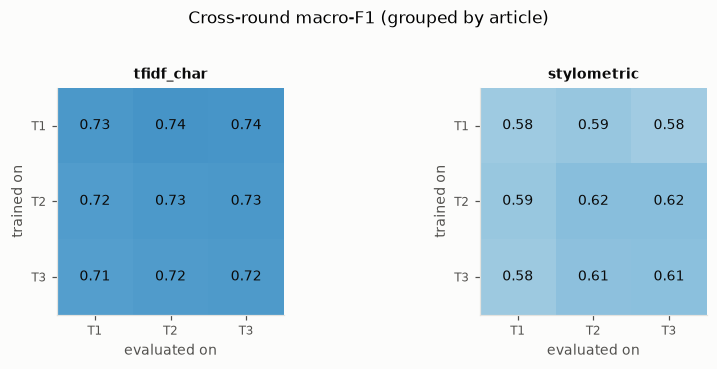

In [6]:
xr = []
for mname in ["tfidf_char", "stylometric"]:
    for s_train in ["T1", "T2", "T3"]:
        p = classify.grouped_cv(pool[pool.stage == s_train], EVALS, "translator", model_kind(mname),
                                cols=MODELS[mname], n_splits=CFG["cv_folds"], repeats=NR, seed=SEED)
        xr.append(p.assign(model=mname, train_stage=s_train, stage=p.eval_set))
xr = pd.concat(xr, ignore_index=True)
xs = classify.scores(xr, ["model", "train_stage", "stage"], LAB, n_boot=500, seed=SEED)
xs.to_csv(OUT / "scores_cross_round.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
for ax, mname in zip(axes, ["tfidf_char", "stylometric"]):
    m = xs[xs.model == mname].pivot(index="train_stage", columns="stage", values="macro_f1")
    ax.imshow(m.to_numpy(), cmap="Blues", vmin=CHANCE, vmax=1)
    ax.grid(False)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{m.iat[i, j]:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if m.iat[i, j] > 0.8 else plots.INK)
    ax.set_xticks(range(3), m.columns)
    ax.set_yticks(range(3), m.index)
    ax.set_xlabel("evaluated on")
    ax.set_ylabel("trained on")
    ax.set_title(mname, fontsize=9)
fig.suptitle("Cross-round macro-F1 (grouped by article)", y=1.03, fontsize=11)
fig.tight_layout()
plots.save(fig, "rq3_cross_round")
plt.show()

## 5. Most predictive features (models fit on all matched texts; interpretation only)

class,MADLAD-400-3B,NLLB-200-1.3B,Qwen3-4B
rank,,,
1,was endorsed,what that,stated
2,endorsed by,have question,stated that
3,endorsed,president have,following
4,was approaching,that what,during
5,approaching,question,finished in
6,approaching the,you,these
7,winning were,dozen gunshots,such as
8,constant,gunshots near,place
9,constant element,gunshots,such


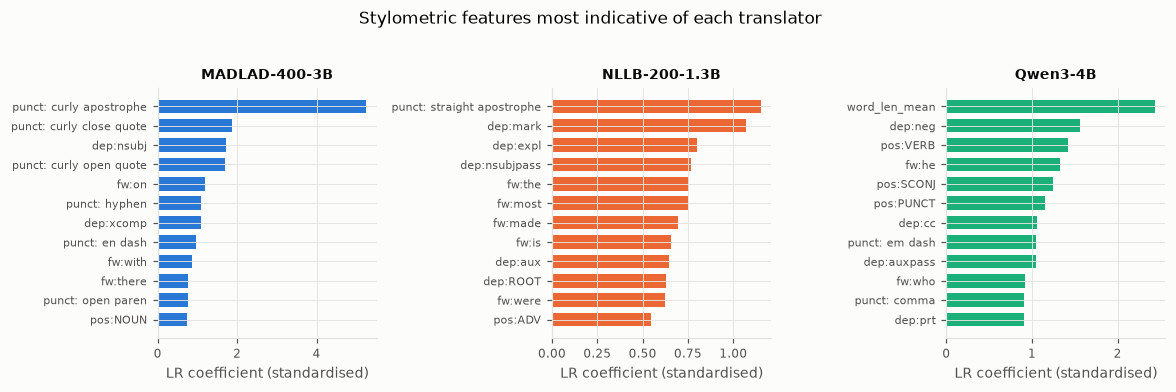

In [7]:
imp = []
for mname, kind in [("tfidf_word", "text"), ("stylometric", "features")]:
    k, est = classify.make_model(mname)
    X = pool["text"] if k == "text" else pool[STYLE].to_numpy(float)
    est.fit(X, pool["translator"])
    imp.append(classify.top_features(est, k, STYLE if k == "features" else None, k=12).assign(model=mname))
imp = pd.concat(imp)
imp.to_csv(OUT / "top_features.csv", index=False)
tw = imp[imp.model == "tfidf_word"].copy()
tw["rank"] = tw.groupby("class").cumcount() + 1
display(tw.assign(**{"class": tw["class"].map(NAMES)}).pivot(index="rank", columns="class", values="feature"))
st = imp[imp.model == "stylometric"]
fig, axes = plt.subplots(1, K, figsize=(3.6 * K, 3.4))
for ax, c in zip(np.atleast_1d(axes), LAB):
    g = st[st["class"] == c].iloc[::-1]
    ax.barh(range(len(g)), g.coef, color=COL[c], height=0.7)
    ax.set_yticks(range(len(g)), [classify.clean_feature_name(f) for f in g.feature], fontsize=7)
    ax.set_title(NAMES[c], fontsize=9)
    ax.set_xlabel("LR coefficient (standardised)")
fig.suptitle("Stylometric features most indicative of each translator", y=1.03, fontsize=11)
fig.tight_layout()
plots.save(fig, "rq3_top_stylometric_features")
plt.show()

## 6. Confound checks: source, length and segmentation

In [8]:
bysrc = classify.scores(preds[preds.model == best], ["source_label"], LAB, n_boot=500, seed=SEED)
display(bysrc[["source_label", "accuracy", "macro_f1", "macro_f1_ci_low", "macro_f1_ci_high", "n_texts"]]
        .set_index("source_label").round(3).rename_axis(index=f"{best}, by original source"))
loso = []
srcs = sorted(pool.source_label.unique())
for mname in ["tfidf_char", "stylometric"]:
    for s in srcs:
        p = classify.grouped_cv(pool, {s: pool[pool.source_label == s]}, "translator", model_kind(mname),
                                cols=MODELS[mname], n_splits=CFG["cv_folds"], repeats=2, seed=SEED,
                                train_filter=lambda tr, s=s: tr[tr.source_label != s])
        loso.append(p.assign(model=mname, held_out_source=s))
loso = pd.concat(loso, ignore_index=True)
ls = classify.scores(loso, ["model", "held_out_source"], LAB, n_boot=300, seed=SEED)
ls.to_csv(OUT / "scores_leave_one_source_out.csv", index=False)
display(ls.pivot_table(index="held_out_source", columns="model", values="macro_f1").round(3)
        .rename_axis(index="leave-one-source-out macro-F1"))
bysrc.to_csv(OUT / "scores_by_source.csv", index=False)

# Typography: curly quotes/apostrophes and long dashes are a surface signal any char model can pick up.
TYPO_CHARS = "\u2018\u2019\u201c\u201d\u2013\u2014"
TYPO = str.maketrans({"\u2018": "'", "\u2019": "'", "\u201c": '"', "\u201d": '"', "\u2013": "-", "\u2014": "-"})
typo_share = pool.groupby(["translator", "stage"]).text.apply(lambda x: x.str.contains(f"[{TYPO_CHARS}]").mean())
display(typo_share.unstack().rename(index=NAMES).round(3).rename_axis(index="share of texts with typographic quotes/dashes"))
t0_typo = en[en.stage == "T0"].text.str.contains(f"[{TYPO_CHARS}]").mean()
print(f"original T0 texts with typographic quotes/dashes: {t0_typo:.3f}")
pool_n = pool.assign(text=pool.text.str.translate(TYPO))
NO_TYPO = [c for c in STYLE if c not in ("punct_11", "punct_12", "punct_13", "punct_14", "punct_15", "punct_16")]
typo_runs = [classify.grouped_cv(pool_n, {x: pool_n[pool_n.stage == x] for x in ["T1", "T2", "T3"]}, "translator",
                                 "tfidf_char", n_splits=CFG["cv_folds"], repeats=NR, seed=SEED).assign(model="tfidf_char_typography_normalised"),
             classify.grouped_cv(pool, EVALS, "translator", "stylometric", cols=NO_TYPO, n_splits=CFG["cv_folds"],
                                 repeats=NR, seed=SEED).assign(model="stylometric_no_typography")]
tp = pd.concat(typo_runs, ignore_index=True)
tp["stage"] = tp.eval_set
ts = pd.concat([classify.scores(tp, ["model", "stage"], LAB, n_boot=500, seed=SEED),
                classify.scores(tp, ["model"], LAB, n_boot=500, seed=SEED).assign(stage="T1-T3")])
ts.to_csv(OUT / "scores_typography_controls.csv", index=False)
scores = pd.concat([scores, ts], ignore_index=True)
scores.to_csv(OUT / "scores_main.csv", index=False)
conf_tab = scores[scores.stage == "T1-T3"].set_index("model")[["macro_f1", "macro_f1_ci_low", "macro_f1_ci_high"]]
display(conf_tab.round(3).rename_axis(index="pooled macro-F1: full vs controls"))

,accuracy,macro_f1,macro_f1_ci_low,macro_f1_ci_high,n_texts
"tfidf_char, by original source",,,,,
BigScience,0.771,0.769,0.702,0.843,252
Eleuther-AI,0.750,0.750,0.663,0.833,234
Human,0.811,0.810,0.738,0.875,261
LLAMA,0.791,0.791,0.695,0.873,243
OpenAI,0.613,0.587,0.499,0.678,252
PaLM,0.706,0.702,0.621,0.777,252
Tsinghua,0.687,0.688,0.601,0.767,243


model,stylometric,tfidf_char
leave-one-source-out macro-F1,,
BigScience,0.626,0.712
Eleuther-AI,0.557,0.761
Human,0.665,0.778
LLAMA,0.629,0.789
OpenAI,0.524,0.554
PaLM,0.550,0.678
Tsinghua,0.501,0.684


stage,T1,T2,T3
share of texts with typographic quotes/dashes,,,
MADLAD-400-3B,0.554,0.585,0.58
NLLB-200-1.3B,0.000,0.000,0.00
Qwen3-4B,0.176,0.140,0.14


original T0 texts with typographic quotes/dashes: 0.005


,macro_f1,macro_f1_ci_low,macro_f1_ci_high
pooled macro-F1: full vs controls,,,
length_only,0.476,0.445,0.504
stylometric,0.603,0.565,0.642
stylometric_no_sentence,0.611,0.570,0.651
tfidf_char,0.730,0.689,0.772
tfidf_word,0.569,0.524,0.616
stylometric_no_typography,0.553,0.516,0.587
tfidf_char_typography_normalised,0.670,0.627,0.714


The confound checks above ask:
- **Length only:** can text length and sentence/word statistics alone identify the translator?
- **Segmentation:** does the stylometric model still work without sentence-boundary features
  (`stylometric_no_sentence` drops sentence-length statistics, the full-stop rate, the ROOT-dependency rate and the
  capitalisation rate)?
- **Source:** does a fingerprint learned on six source labels transfer to texts of the seventh, unseen source
  (leave-one-source-out)?
- **Typography:** does the fingerprint survive when curly quotes, apostrophes and long dashes are normalised to
  ASCII (character model), or when those punctuation rates are removed (stylometric model)?

## 7. Key results

In [9]:
def get(s, m, st):
    r = s[(s.model == m) & (s.stage == st)].iloc[0]
    return f"{r.macro_f1:.3f} [{r.macro_f1_ci_low:.3f}, {r.macro_f1_ci_high:.3f}]"
lines = [f"- K = {K} translators (chance {CHANCE:.3f}); {pool.item_id.nunique()} matched documents, "
         f"{pool.article_id.nunique()} articles, {len(pool)} texts."]
for m in MODELS:
    lines.append(f"- **{m}**: T1 {get(sc, m, 'T1')}, T2 {get(sc, m, 'T2')}, T3 {get(sc, m, 'T3')}.")
display(Markdown("\n".join(lines)))
preds.to_parquet(OUT / "predictions.parquet", index=False)
json.dump({"classes": TR, "chance": CHANCE, "models": list(MODELS), "best_model": best, "seed": SEED,
           "folds": CFG["cv_folds"], "repeats": NR, "cohort": "matched", "texts": int(len(pool))},
          open(OUT / "config.json", "w"), indent=1)

- K = 3 translators (chance 0.333); 193 matched documents, 31 articles, 1737 texts.
- **tfidf_word**: T1 0.549 [0.506, 0.590], T2 0.575 [0.526, 0.621], T3 0.583 [0.535, 0.631].
- **tfidf_char**: T1 0.723 [0.676, 0.766], T2 0.732 [0.689, 0.771], T3 0.736 [0.693, 0.782].
- **stylometric**: T1 0.588 [0.548, 0.626], T2 0.610 [0.569, 0.646], T3 0.611 [0.567, 0.656].
- **stylometric_no_sentence**: T1 0.597 [0.558, 0.637], T2 0.618 [0.579, 0.659], T3 0.618 [0.574, 0.658].
- **length_only**: T1 0.449 [0.417, 0.477], T2 0.478 [0.450, 0.507], T3 0.501 [0.466, 0.533].

## Interpretation

Scores are macro-F1 on the matched cohort (193 documents × 3 translators × 3 rounds = 1,737 texts, 31 articles,
5×5 grouped CV). Chance is 1/K = 0.333.

**1. Translators leave a clear, stable fingerprint.**
- The character n-gram model identifies the translator with macro-F1 0.73 (accuracy 0.73) on articles it never saw.
- The fingerprint is the same at every round (T1 0.72, T2 0.73, T3 0.74) and transfers across rounds: a model
  trained on T1 scores 0.74 on T3.
- The fingerprint is set in the first round trip and then persists, consistent with the fixed-point behaviour in
  RQ1.

**2. Part of the fingerprint is typography and orthography.**
- MADLAD introduces typographic quotes and apostrophes (’ “ ”) in about 58% of its texts, Qwen in about 15%, and NLLB
  in none (0.5% of originals).
- The curly apostrophe is MADLAD's single strongest stylometric feature.
- Normalising these characters to ASCII lowers the character model from 0.73 to **0.67**. Removing them from the
  stylometric model lowers it from 0.60 to 0.55.
- The fingerprint survives both controls, well above chance. It is also lexical and syntactic:
  - Qwen prefers "stated (that)", "following" and "such as", and longer words;
  - NLLB has more subordinate markers and expletives, and a characteristic "what that" construction.

**3. It is not a length or segmentation artefact.**
- **Length:** a length and sentence-statistics control reaches 0.48, above chance but far below the text models.
- **Segmentation:** removing sentence-boundary features slightly *improves* the stylometric model (0.61 vs 0.60), so
  the fingerprint does not rely on the MT-vs-LLM segmentation difference.
- **Per-class:** Qwen is the easiest class (F1 0.78). NLLB is the most precise (0.86) but least recalled (0.58): its
  outputs are often taken for MADLAD.

**4. It generalises across original sources.**
- Training on six source labels and testing on the seventh keeps the character model between 0.55 (OpenAI) and 0.79
  (LLAMA).
- The weakest held-out source, OpenAI, has the shortest texts (median 108 words), which carry the least evidence.

## Limitations
- **Clustering:** all scores are clustered on 31 articles, and CIs are about ±0.04.
- **Three translators only:** two MT systems and one LLM. Phi-4-mini will be added automatically, and the chance
  level and class set update with it.
- **Feature importance:** the important-feature lists come from models fit on all texts. They describe the
  classifier and are not causal. Some word n-grams are content-specific to a few documents.
- **Generalisation scope:** the fingerprint is measured on XSum news via English↔Spanish only. Other genres, language
  pairs or decoding settings may change it.
- **Training material:** classifiers are trained on round-trip outputs of these specific checkpoints. Their
  robustness to post-editing or other model versions is untested.